# 🏠 EDA – PHÒNG TRỌ (Đà Nẵng)
**Mục tiêu:** khám phá dữ liệu `rental_room_rows4.csv` trước khi huấn luyện mô hình dự đoán giá thuê.

| Bước | Nội dung |
|---|---|
| 1 | Tải & làm sạch dữ liệu (phễu lọc) |
| 2 | Phân bổ **thuộc tính liên tục** (lệch? đuôi dài? có cần log?) |
| 3 | Phân bổ **thuộc tính rời rạc / nhãn** (có cân bằng không?) |
| 4 | Quan hệ **tuyến tính hay phi tuyến** với giá (đường hồi quy tuyến tính vs LOWESS vs spline) |
| 5 | **Ma trận tương quan & heatmap** (Pearson, Spearman, Mutual Information) |
| 6 | Ảnh hưởng của **khoảng cách tới trường ĐH & biển** theo từng khoảng (0–1, **1–2**, **2–6** km) |
| 7 | Biến phân loại (phường, biển, trường, nội thất) & bản đồ giá |
| 8 | Tổng kết & gợi ý cho bước huấn luyện |

In [36]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
import statsmodels.formula.api as smf
from sklearn.preprocessing import SplineTransformer, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, KFold
from sklearn.feature_selection import mutual_info_regression

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.labelsize": 10, "figure.facecolor": "white"})
PAL = sns.color_palette("Set2")
C_LIN, C_LOW, C_SPL = "#E63946", "#2A9D8F", "#7B2CBF"   # đỏ = tuyến tính, xanh ngọc = LOWESS, tím = spline


def logax(ax, which="y"):
    """Thang log với nhiều nhãn dễ đọc (triệu VND)."""
    ticks = [.5, 1, 1.5, 2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 100]
    a = ax.yaxis if which == "y" else ax.xaxis
    (ax.set_yscale if which == "y" else ax.set_xscale)("log")
    a.set_major_locator(mtick.FixedLocator(ticks)); a.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
    a.set_minor_formatter(mtick.NullFormatter())

# ---------------- CẤU HÌNH ----------------
CSV_PATH      = "rental_room_rows.csv"
CATEGORY      = "Phòng trọ"
YEARS         = [2025, 2026]
EXCLUDE_WARDS = ['Hải Vân']
DEDUP_COLS    = ['latitude', 'longitude', 'price_vnd', 'size_m2', 'furnishing_status']
IQR_K         = 1.5

## 1️⃣ Tải & làm sạch dữ liệu
Logic lọc giống script huấn luyện để EDA phản ánh đúng dữ liệu mô hình sẽ thấy.

Toàn bộ file: (4158, 30)


,số dòng
category_name,
Căn hộ/Chung cư,2264
Phòng trọ,1894


,Bước,Số dòng còn lại,Bị loại
0,Đúng loại hình,1894,0
1,"Năm [2025, 2026]",1374,520
2,Bỏ phường ['Hải Vân'],1346,28
3,Bỏ trùng lặp,1293,53
4,Bỏ giá/diện tích phi lý,1286,7
5,Bỏ outlier IQR (log giá & diện tích),1190,96


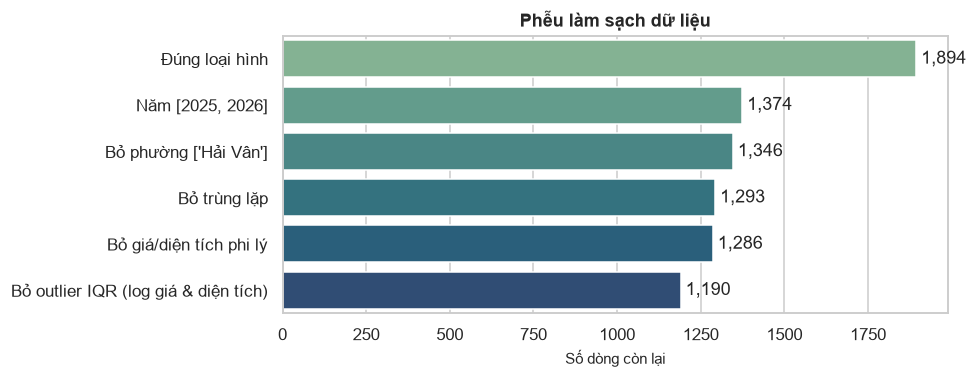

In [37]:
raw = pd.read_csv(CSV_PATH)
print("Toàn bộ file:", raw.shape)
display(raw.category_name.value_counts().to_frame("số dòng"))

df = raw[raw["category_name"] == CATEGORY].copy()
funnel = [("Đúng loại hình", len(df))]

df["posted_date"] = pd.to_datetime(df["posted_date"], format="mixed")
df = df[df["posted_date"].dt.year.isin(YEARS)].copy();            funnel.append((f"Năm {YEARS}", len(df)))
if EXCLUDE_WARDS:
    df = df[~df["ward_name"].isin(EXCLUDE_WARDS)];                funnel.append((f"Bỏ phường {EXCLUDE_WARDS}", len(df)))
df = df.drop_duplicates(DEDUP_COLS);                              funnel.append(("Bỏ trùng lặp", len(df)))

# Dữ liệu có giá trị phi lý (vd. size_m2 = 9e11, giá = 1.700 VND) -> loại trước khi tính IQR
df = df[(df.size_m2.between(5, 500)) & (df.price_vnd >= 300_000)];  funnel.append(("Bỏ giá/diện tích phi lý", len(df)))
df["log_price"] = np.log(df["price_vnd"])

def iqr_mask(s, k=IQR_K):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return s.between(q1 - k*i, q3 + k*i)
df = df[iqr_mask(df.log_price) & iqr_mask(df.size_m2)].reset_index(drop=True)
funnel.append(("Bỏ outlier IQR (log giá & diện tích)", len(df)))

# Thêm biến phụ
df["price_m"]  = df.price_vnd / 1e6                 # triệu VND (dễ đọc)
df["log_size"] = np.log(df.size_m2)
FURN_ORDER = ["Không nội thất", "Nội thất cơ bản", "Đầy đủ nội thất", "Nội thất cao cấp", "Không xác định"]
df["furn_code"] = df.furnishing_status.map({k: i for i, k in enumerate(FURN_ORDER)})

fn = pd.DataFrame(funnel, columns=["Bước", "Số dòng còn lại"])
fn["Bị loại"] = (-fn["Số dòng còn lại"].diff()).fillna(0).astype(int)
display(fn)
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.barplot(data=fn, y="Bước", x="Số dòng còn lại", palette="crest", ax=ax)
for p, v in zip(ax.patches, fn["Số dòng còn lại"]): ax.text(v, p.get_y()+p.get_height()/2, f" {v:,}", va="center")
ax.set_title("Phễu làm sạch dữ liệu"); ax.set_ylabel(""); plt.tight_layout(); plt.show()

In [38]:
# Phân loại thuộc tính
CONT = ["size_m2", "dist_to_cbd", "dist_to_beach", "dist_to_nearest_uni", "dist_to_airport"]
BIN_ALL = ["has_balcony", "has_elevator", "has_window", "has_mezzanine", "private_bathroom",
           "wifi", "has_parking", "free_hours", "has_camera_security"]
BIN  = [b for b in BIN_ALL if df[b].nunique() > 1]
ORD  = ["rooms"] if df.rooms.nunique() > 1 else []
CAT  = ["furnishing_status", "ward_name", "nearest_beach_code", "nearest_uni_code"]
const = [c for c in df.columns if df[c].nunique() <= 1]
print("Liên tục :", CONT); print("Nhị phân :", BIN); print("Thứ tự   :", ORD); print("Phân loại:", CAT)
print("Cột hằng số (bỏ qua):", const)
print("Thiếu dữ liệu:", int(df[CONT+BIN+ORD+CAT].isna().sum().sum()), "ô")
display(df[["price_m", "size_m2"] + CONT[1:]].describe().T.round(2))

Liên tục : ['size_m2', 'dist_to_cbd', 'dist_to_beach', 'dist_to_nearest_uni', 'dist_to_airport']
Nhị phân : ['has_balcony', 'has_elevator', 'has_window', 'has_mezzanine', 'private_bathroom', 'wifi', 'has_parking', 'free_hours', 'has_camera_security']
Thứ tự   : []
Phân loại: ['furnishing_status', 'ward_name', 'nearest_beach_code', 'nearest_uni_code']
Cột hằng số (bỏ qua): ['rooms', 'category_name', 'flooded_2022', 'flooded_2025', 'flood_risk_label']
Thiếu dữ liệu: 0 ô


,count,mean,std,min,25%,50%,75%,max
price_m,1190.0,3.33,1.33,1.10,2.50,3.10,4.00,8.50
size_m2,1190.0,24.92,7.68,10.00,20.00,25.00,30.00,45.00
dist_to_cbd,1190.0,5.05,2.75,0.18,2.65,4.94,7.01,15.07
dist_to_beach,1190.0,3.08,1.75,0.16,1.66,2.87,4.28,8.22
dist_to_nearest_uni,1190.0,1.89,1.32,0.04,0.89,1.56,2.66,8.21
dist_to_airport,1190.0,4.93,2.25,1.00,3.05,4.78,6.51,14.74


## 2️⃣ Phân bổ thuộc tính liên tục
Mỗi hàng gồm 3 biểu đồ: **(trái)** phân bổ gốc + KDE, **(giữa)** sau biến đổi `log`, **(phải)** boxplot để thấy outlier.
- **Skewness > 1** → lệch phải mạnh → nên cân nhắc `log` (với mô hình tuyến tính) – mô hình cây không cần.
- Đường **đỏ** = trung bình, **xanh** = trung vị.

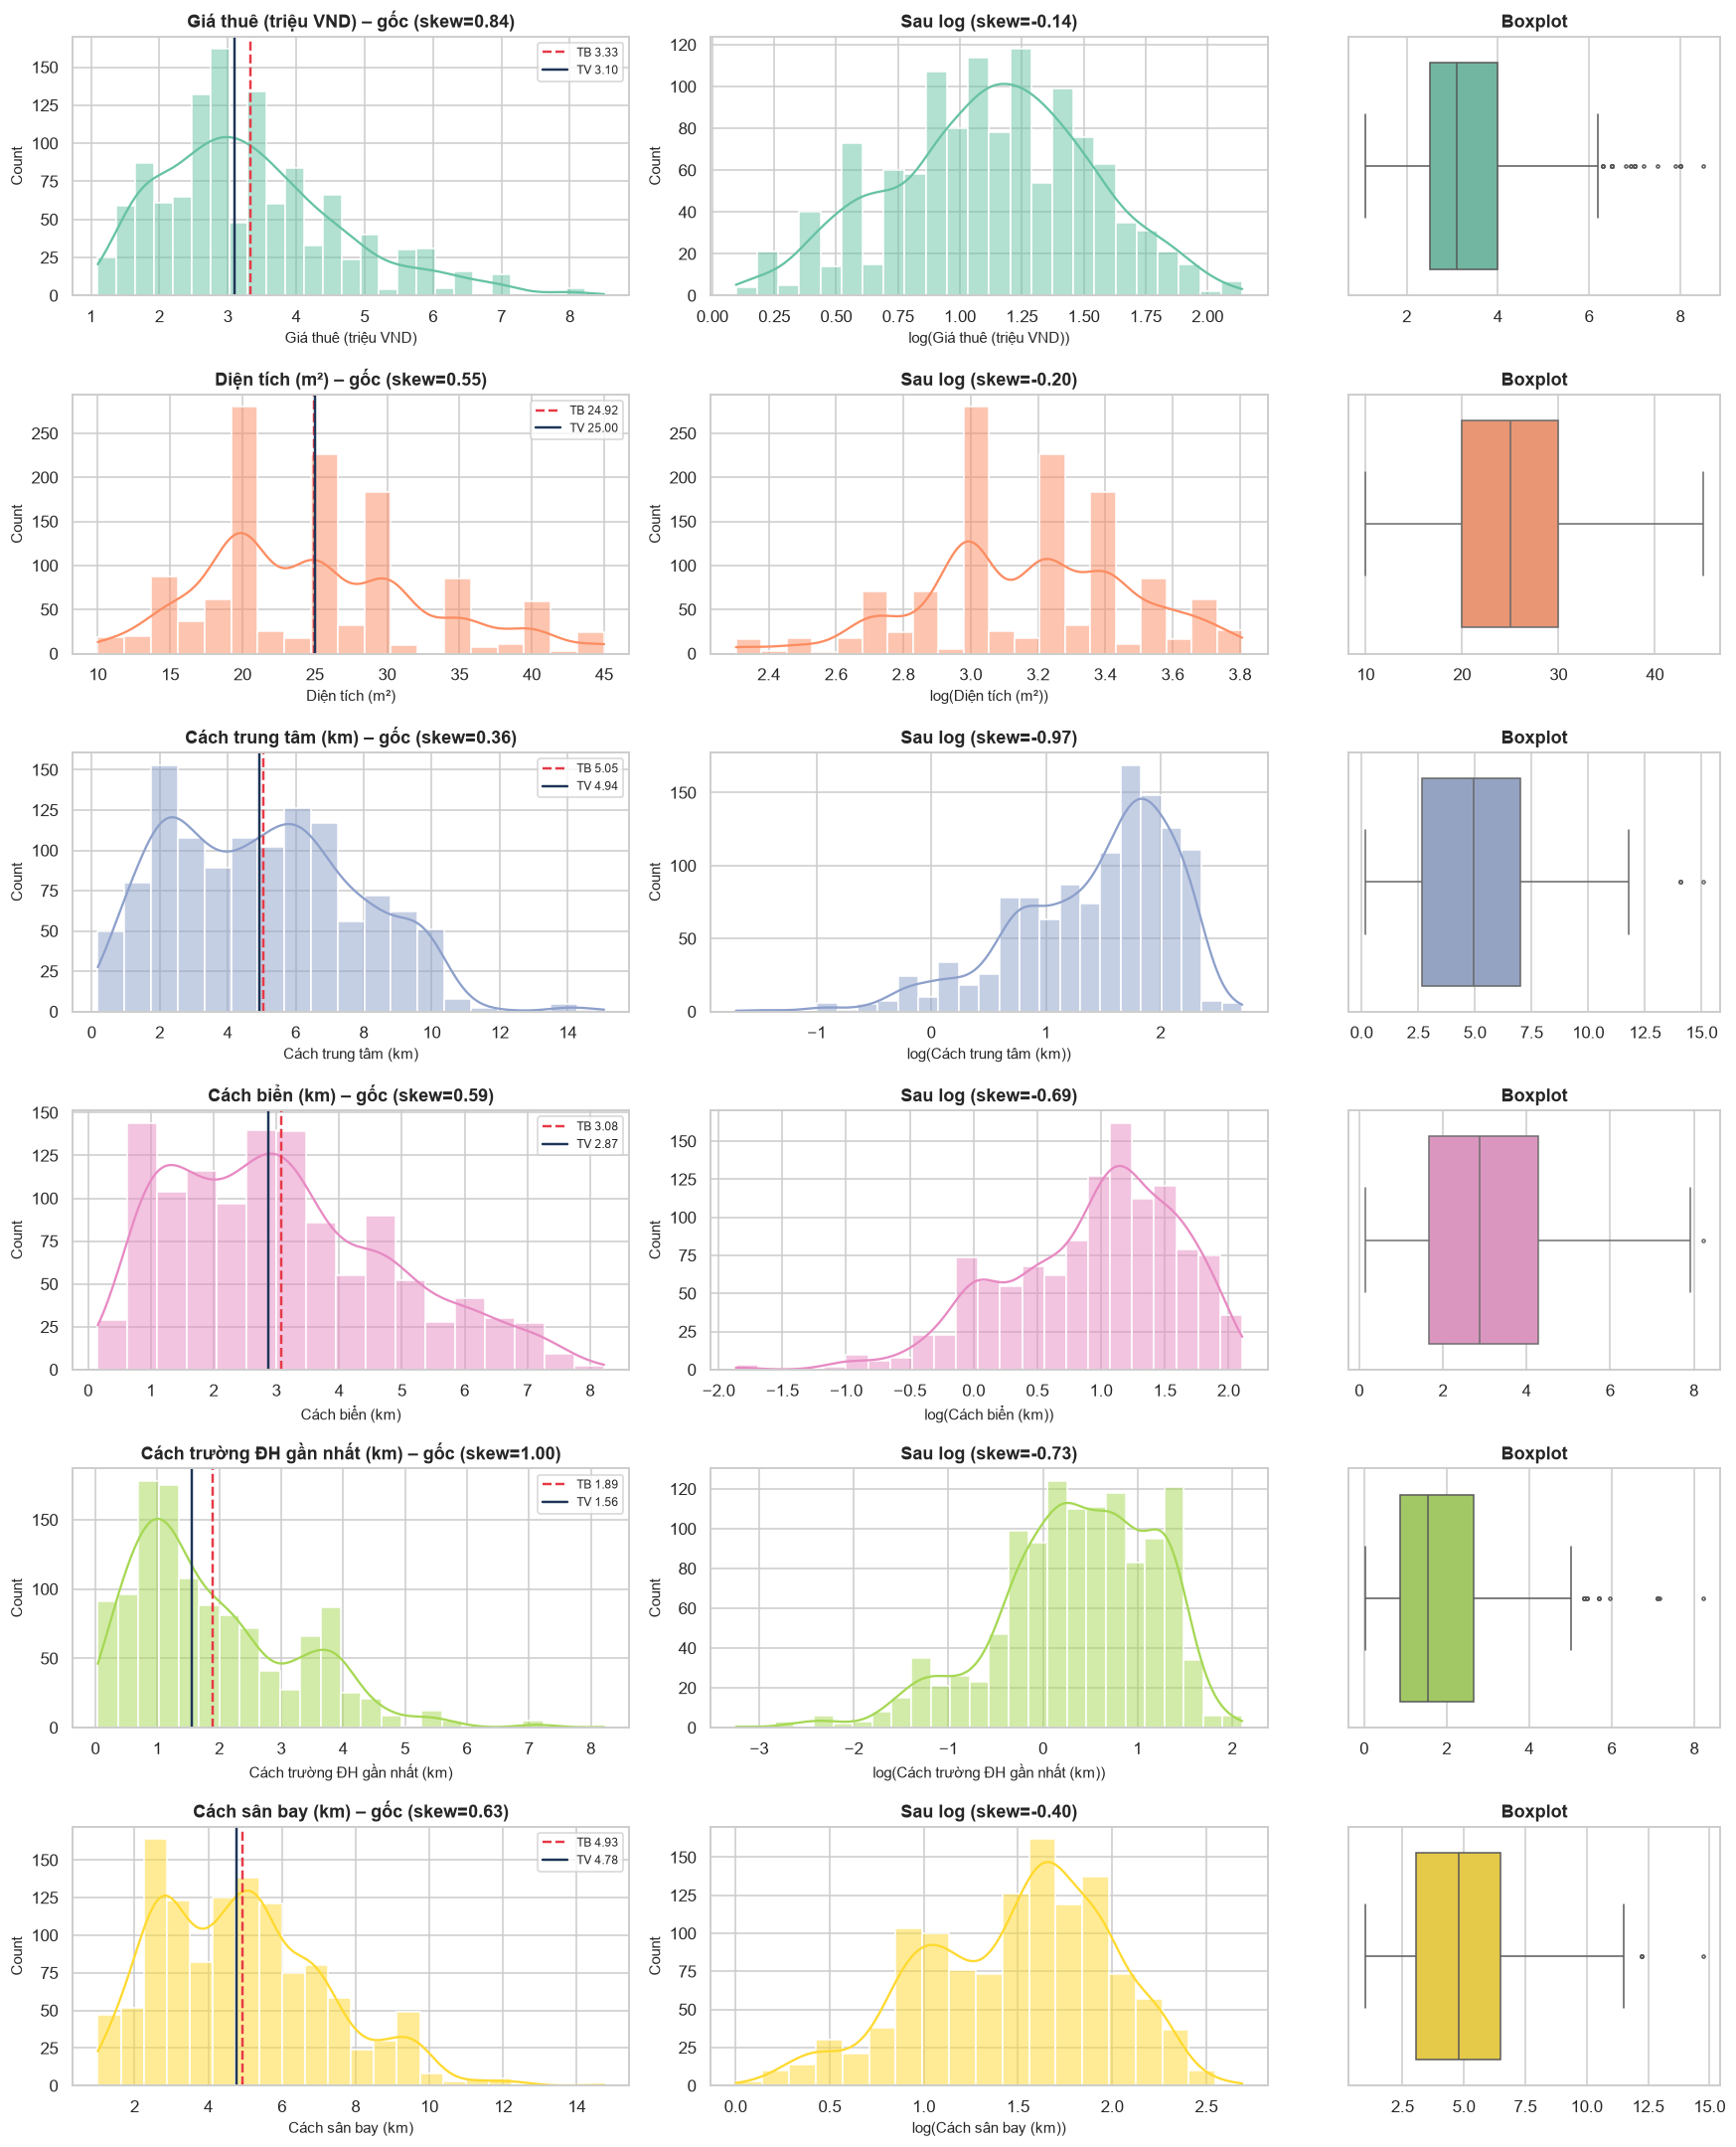

In [39]:
feats = ["price_m"] + CONT
labels = {"price_m": "Giá thuê (triệu VND)", "size_m2": "Diện tích (m²)", "dist_to_cbd": "Cách trung tâm (km)",
          "dist_to_beach": "Cách biển (km)", "dist_to_nearest_uni": "Cách trường ĐH gần nhất (km)",
          "dist_to_airport": "Cách sân bay (km)"}
fig, axes = plt.subplots(len(feats), 3, figsize=(16, 3.3*len(feats)), gridspec_kw={"width_ratios": [1.2, 1.2, .8]})
for i, f in enumerate(feats):
    col = PAL[i % 8]; s = df[f]
    sns.histplot(s, kde=True, color=col, ax=axes[i, 0], edgecolor="white")
    axes[i, 0].axvline(s.mean(), color="#E63946", ls="--", lw=1.6, label=f"TB {s.mean():.2f}")
    axes[i, 0].axvline(s.median(), color="#1D3557", ls="-", lw=1.6, label=f"TV {s.median():.2f}")
    axes[i, 0].legend(fontsize=8); axes[i, 0].set(xlabel=labels[f], title=f"{labels[f]} – gốc (skew={s.skew():.2f})")
    sns.histplot(np.log(s), kde=True, color=col, ax=axes[i, 1], edgecolor="white")
    axes[i, 1].set(xlabel=f"log({labels[f]})", title=f"Sau log (skew={np.log(s).skew():.2f})")
    sns.boxplot(x=s, color=col, ax=axes[i, 2], fliersize=2); axes[i, 2].set(xlabel="", title="Boxplot")
plt.tight_layout(); plt.show()

In [40]:
rows = []
for f in feats:
    s = df[f]; sk, sl = s.skew(), np.log(s).skew()
    p = stats.normaltest(s)[1]; pl = stats.normaltest(np.log(s))[1]
    rows.append(dict(thuoc_tinh=f, trung_binh=s.mean(), trung_vi=s.median(), do_lech_chuan=s.std(), skew=sk, kurtosis=s.kurt(),
                     skew_sau_log=sl, chuan_p_goc=p, chuan_p_log=pl,
                     nhan_xet=("Lệch phải mạnh → nên log" if sk > 1 else "Lệch phải vừa" if sk > .5 else "Gần đối xứng")))
sk_tbl = pd.DataFrame(rows).set_index("thuoc_tinh")
display(sk_tbl.round(3).style.background_gradient(subset=["skew", "skew_sau_log"], cmap="RdYlGn_r", vmin=-1, vmax=3)
        .format({"chuan_p_goc": "{:.1e}", "chuan_p_log": "{:.1e}"}))

,trung_binh,trung_vi,do_lech_chuan,skew,kurtosis,skew_sau_log,chuan_p_goc,chuan_p_log,nhan_xet
thuoc_tinh,,,,,,,,,
price_m,3.331000,3.100000,1.331000,0.839000,0.633000,-0.138000,0.0e+00,0.0e+00,Lệch phải vừa
size_m2,24.915000,25.000000,7.679000,0.547000,-0.180000,-0.201000,0.0e+00,8.0e-03,Lệch phải vừa
dist_to_cbd,5.049000,4.938000,2.747000,0.357000,-0.527000,-0.971000,0.0e+00,0.0e+00,Gần đối xứng
dist_to_beach,3.084000,2.873000,1.753000,0.590000,-0.389000,-0.691000,0.0e+00,0.0e+00,Lệch phải vừa
dist_to_nearest_uni,1.894000,1.559000,1.319000,0.996000,0.799000,-0.732000,0.0e+00,0.0e+00,Lệch phải vừa
dist_to_airport,4.933000,4.776000,2.247000,0.628000,0.084000,-0.396000,0.0e+00,0.0e+00,Lệch phải vừa


## 3️⃣ Phân bổ thuộc tính rời rạc / nhãn
Kiểm tra **mức cân bằng** của từng nhãn: nhãn quá hiếm (<5%) khó học và nên cân nhắc gộp nhóm. Biểu đồ bên phải cho biết **giá trung vị chênh bao nhiêu %** khi có tiện ích đó (kèm kiểm định Mann–Whitney).

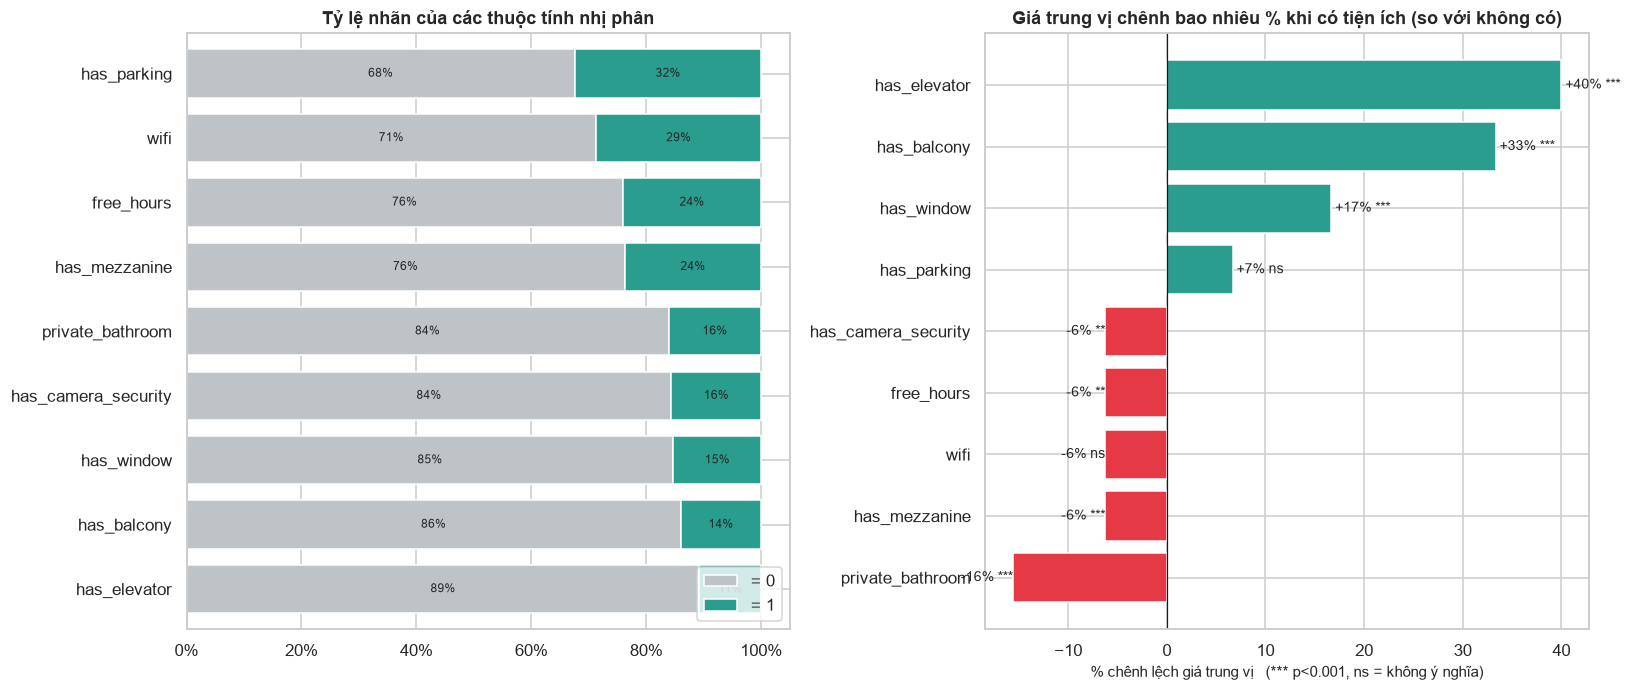

In [41]:
disc = BIN + ORD
fig, axes = plt.subplots(1, 2, figsize=(15, max(4, .55*len(disc)+1.5)))
# (a) tỷ lệ các nhãn
shares = pd.DataFrame({f: df[f].value_counts(normalize=True).sort_index() for f in BIN}).T.fillna(0)
shares.columns = [f"= {int(c)}" for c in shares.columns]
shares.sort_values("= 1").plot.barh(stacked=True, color=["#BDC3C7", "#2A9D8F"], ax=axes[0], width=.75)
for p in axes[0].patches:
    if p.get_width() > .06: axes[0].text(p.get_x()+p.get_width()/2, p.get_y()+p.get_height()/2, f"{p.get_width():.0%}", ha="center", va="center", fontsize=8)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].set_title("Tỷ lệ nhãn của các thuộc tính nhị phân"); axes[0].legend(loc="lower right")
# (b) chênh lệch giá trung vị
res = []
for f in BIN:
    a, b = df.loc[df[f] == 1, "log_price"], df.loc[df[f] == 0, "log_price"]
    res.append(dict(f=f, pct=(np.exp(a.median()-b.median())-1)*100, p=stats.mannwhitneyu(a, b)[1], n1=len(a)))
res = pd.DataFrame(res).sort_values("pct")
cols = ["#2A9D8F" if v > 0 else "#E63946" for v in res.pct]
axes[1].barh(res.f, res.pct, color=cols)
for y, (v, p) in enumerate(zip(res.pct, res.p)):
    star = "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"
    axes[1].text(v, y, f" {v:+.0f}% {star}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
axes[1].axvline(0, color="k", lw=.8); axes[1].set_title("Giá trung vị chênh bao nhiêu % khi có tiện ích (so với không có)")
axes[1].set_xlabel("% chênh lệch giá trung vị   (*** p<0.001, ns = không ý nghĩa)")
plt.tight_layout(); plt.show()

## 4️⃣ Quan hệ với giá: **tuyến tính hay phi tuyến?**
Mỗi biểu đồ vẽ giá (thang log, theo triệu VND) theo từng thuộc tính liên tục, với:
- 🔴 **Đường hồi quy tuyến tính** (OLS trên log-giá),
- 🟢 **LOWESS** – đường cong mượt không giả định hình dạng,
- 🟣 **Spline bậc 3** (kết quả của mô hình phi tuyến tham số),
- Màu điểm = mật độ (vàng càng đậm = càng nhiều điểm).

Nếu đường xanh lá **lệch hẳn** khỏi đường đỏ → quan hệ **phi tuyến**. Định lượng bằng **ΔR² (CV) = R² spline − R² tuyến tính**.

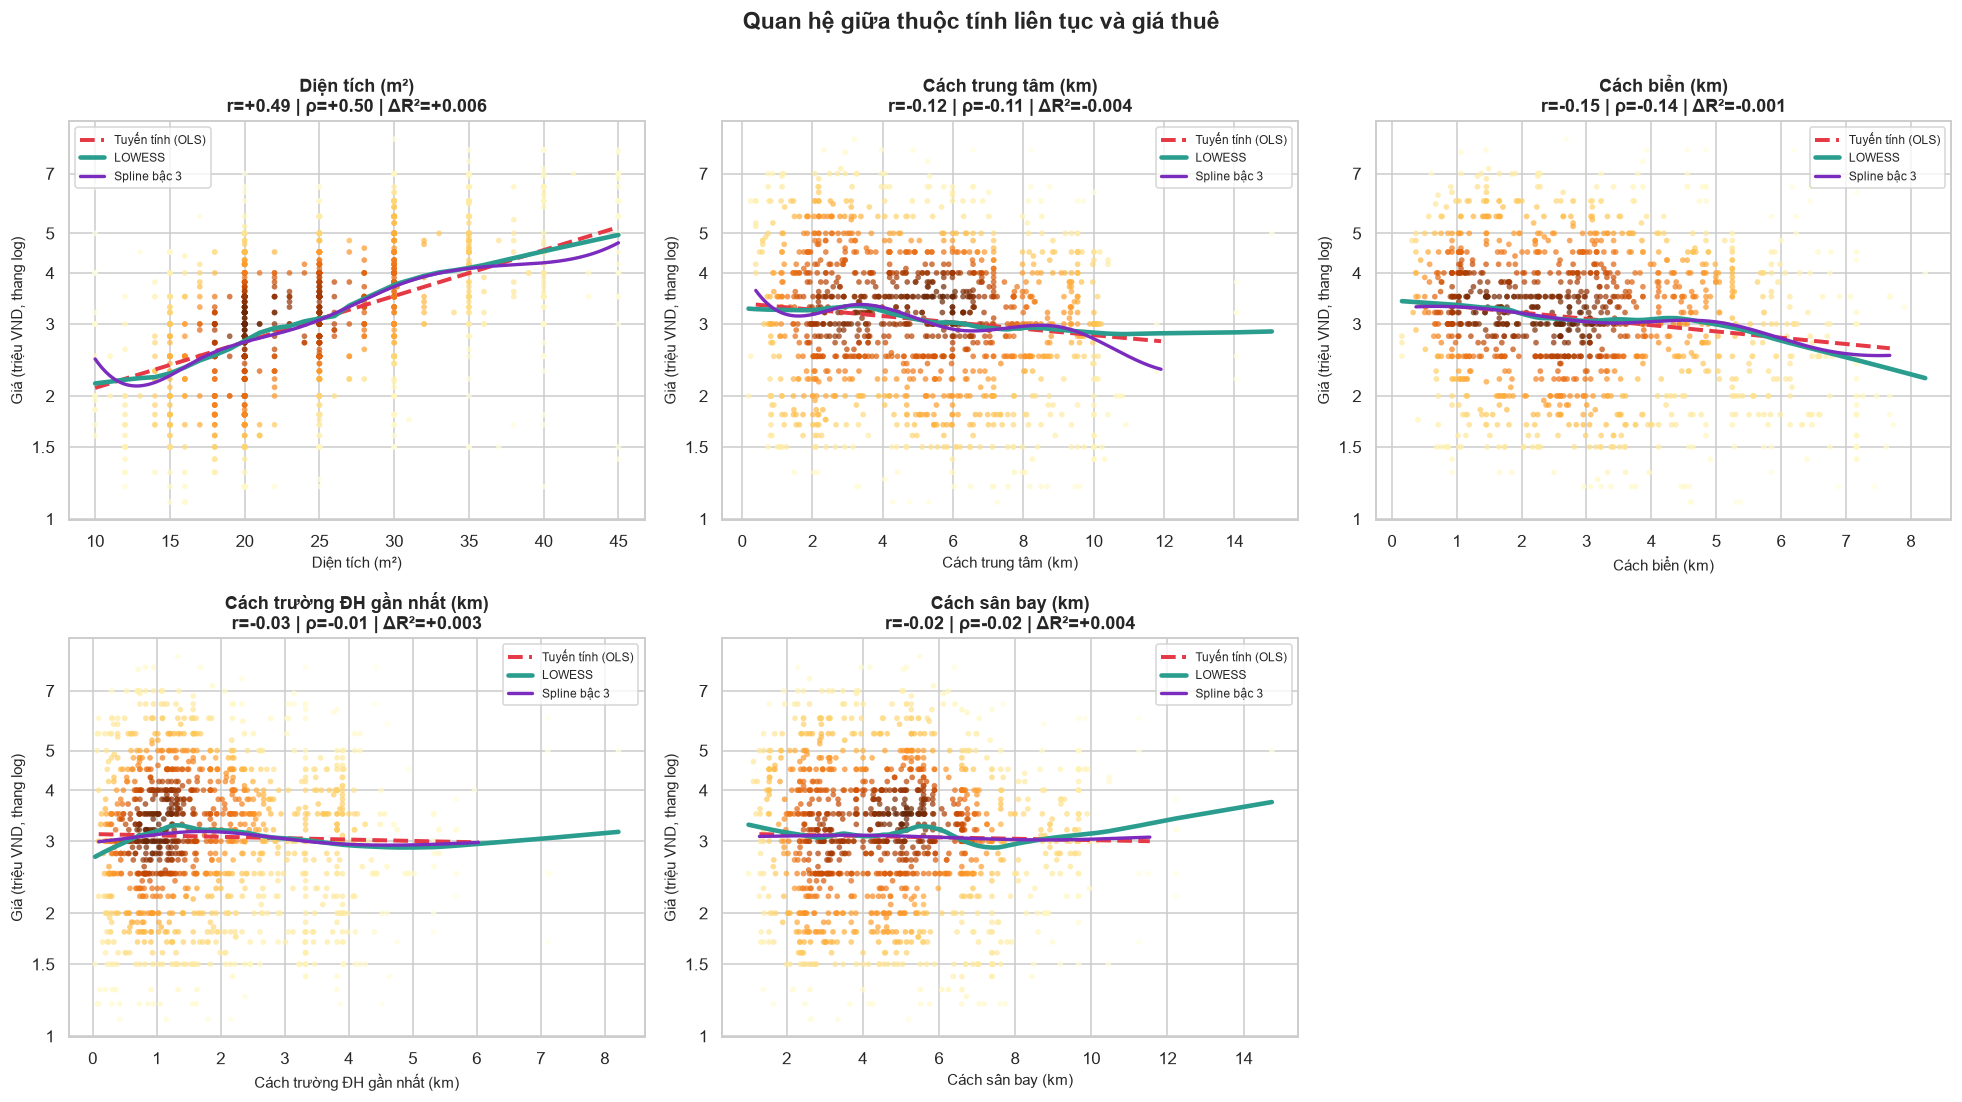

In [42]:
def cv_r2(x, y, model):
    kf = KFold(5, shuffle=True, random_state=42)
    return cross_val_score(model, x.values.reshape(-1, 1), y, cv=kf, scoring="r2").mean()

def lin_vs_nonlin(df, f, y="log_price"):
    x, yy = df[f], df[y]
    r2_lin = cv_r2(x, yy, LinearRegression())
    r2_log = cv_r2(np.log(x), yy, LinearRegression()) if (x > 0).all() else np.nan
    r2_spl = cv_r2(x, yy, make_pipeline(SplineTransformer(n_knots=6, degree=3), RidgeCV(alphas=np.logspace(-3, 2, 12))))
    return dict(pearson=stats.pearsonr(x, yy)[0], spearman=stats.spearmanr(x, yy)[0],
                R2_tuyen_tinh=r2_lin, R2_log_x=r2_log, R2_spline=r2_spl, delta_R2=r2_spl - r2_lin)

fig, axes = plt.subplots(2, 3, figsize=(18, 10)); axes = axes.ravel()
nl_rows = {}
for ax, f in zip(axes, CONT):
    x, y = df[f].values, df.log_price.values
    # màu theo mật độ
    xy = np.vstack([(x-x.mean())/x.std(), (y-y.mean())/y.std()]); dens = stats.gaussian_kde(xy)(xy)
    o = dens.argsort()
    ax.scatter(x[o], np.exp(y[o])/1e6, c=dens[o], s=14, cmap="YlOrBr", alpha=.7, edgecolor="none")
    xs = np.linspace(np.percentile(x, 0.5), np.percentile(x, 99.5), 300)
    b1, b0 = np.polyfit(x, y, 1); ax.plot(xs, np.exp(b0+b1*xs)/1e6, color=C_LIN, lw=2.6, ls="--", label="Tuyến tính (OLS)")
    lw = lowess(y, x, frac=.4, it=1); ax.plot(lw[:, 0], np.exp(lw[:, 1])/1e6, color=C_LOW, lw=3, label="LOWESS")
    spl = make_pipeline(SplineTransformer(n_knots=6, degree=3), RidgeCV(alphas=np.logspace(-3, 2, 12))).fit(x.reshape(-1, 1), y)
    ax.plot(xs, np.exp(spl.predict(xs.reshape(-1, 1)))/1e6, color=C_SPL, lw=2.2, label="Spline bậc 3")
    logax(ax, "y")
    m = lin_vs_nonlin(df, f); nl_rows[f] = m
    ax.set(xlabel=labels[f], ylabel="Giá (triệu VND, thang log)",
           title=f"{labels[f]}\nr={m['pearson']:+.2f} | ρ={m['spearman']:+.2f} | ΔR²={m['delta_R2']:+.3f}")
    ax.legend(fontsize=8)
for ax in axes[len(CONT):]: ax.axis("off")
plt.suptitle("Quan hệ giữa thuộc tính liên tục và giá thuê", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

,pearson,spearman,R2_tuyen_tinh,R2_log_x,R2_spline,delta_R2,ket_luan
size_m2,0.495000,0.498000,0.237000,0.231000,0.244000,0.006000,Hơi phi tuyến
dist_to_cbd,-0.123000,-0.113000,0.010000,0.009000,0.005000,-0.004000,Gần tuyến tính
dist_to_beach,-0.155000,-0.136000,0.017000,0.012000,0.016000,-0.001000,Gần tuyến tính
dist_to_nearest_uni,-0.025000,-0.008000,-0.003000,-0.004000,-0.000000,0.003000,Gần tuyến tính (yếu)
dist_to_airport,-0.022000,-0.022000,-0.004000,-0.004000,-0.000000,0.004000,Gần tuyến tính (yếu)


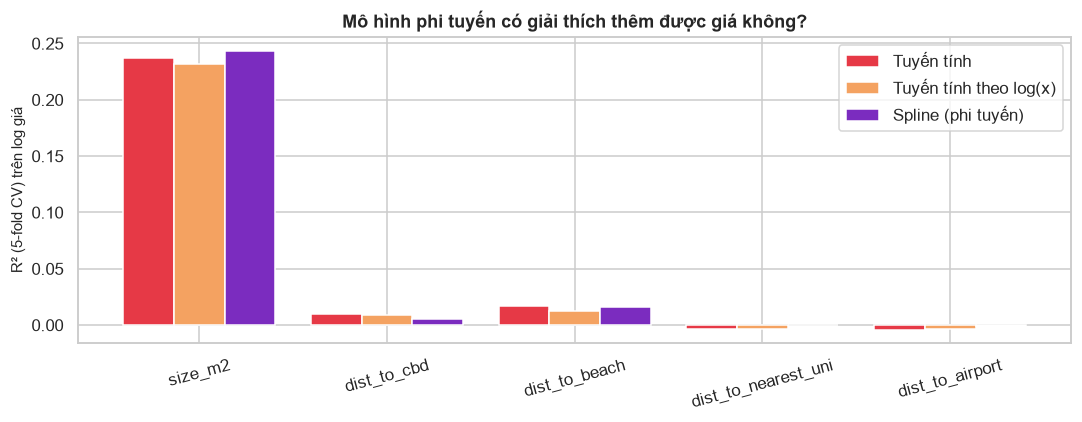

In [43]:
nl = pd.DataFrame(nl_rows).T
nl["ket_luan"] = np.where(nl.delta_R2 > .02, "PHI TUYẾN rõ", np.where(nl.delta_R2 > .005, "Hơi phi tuyến", "Gần tuyến tính"))
nl.loc[nl.pearson.abs() < .1, "ket_luan"] += " (yếu)"
display(nl.round(3).style.background_gradient(subset=["delta_R2"], cmap="Purples").background_gradient(subset=["pearson", "spearman"], cmap="RdBu", vmin=-.8, vmax=.8))

fig, ax = plt.subplots(figsize=(10, 4))
w = .27; xs_ = np.arange(len(nl))
ax.bar(xs_-w, nl.R2_tuyen_tinh, w, color=C_LIN, label="Tuyến tính")
ax.bar(xs_, nl.R2_log_x, w, color="#F4A261", label="Tuyến tính theo log(x)")
ax.bar(xs_+w, nl.R2_spline, w, color=C_SPL, label="Spline (phi tuyến)")
ax.set_xticks(xs_); ax.set_xticklabels(nl.index, rotation=15); ax.set_ylabel("R² (5-fold CV) trên log giá")
ax.set_title("Mô hình phi tuyến có giải thích thêm được giá không?"); ax.legend(); plt.tight_layout(); plt.show()

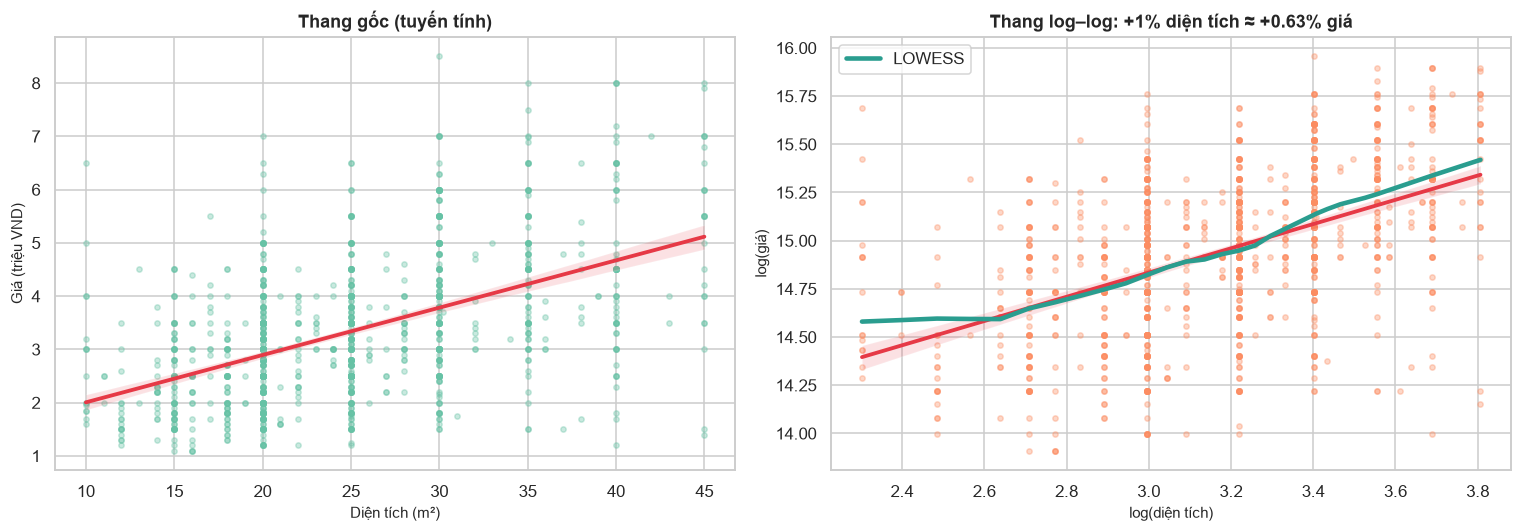

In [44]:
# Với diện tích: kiểm tra riêng quan hệ log–log (độ co giãn giá theo diện tích)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(x="size_m2", y="price_m", data=df, scatter_kws=dict(s=12, alpha=.35, color=PAL[0]), line_kws=dict(color=C_LIN, lw=2.5), ax=axes[0])
axes[0].set(title="Thang gốc (tuyến tính)", xlabel="Diện tích (m²)", ylabel="Giá (triệu VND)")
sns.regplot(x="log_size", y="log_price", data=df, lowess=False, scatter_kws=dict(s=12, alpha=.35, color=PAL[1]), line_kws=dict(color=C_LIN, lw=2.5), ax=axes[1])
lw = lowess(df.log_price, df.log_size, frac=.4); axes[1].plot(lw[:, 0], lw[:, 1], color=C_LOW, lw=3, label="LOWESS")
b = np.polyfit(df.log_size, df.log_price, 1)[0]
axes[1].set(title=f"Thang log–log: +1% diện tích ≈ +{b:.2f}% giá", xlabel="log(diện tích)", ylabel="log(giá)"); axes[1].legend()
plt.tight_layout(); plt.show()

## 5️⃣ Ma trận tương quan & heatmap
- **Pearson**: tương quan tuyến tính. **Spearman**: tương quan đơn điệu (bắt được quan hệ cong nhưng một chiều).
- **Mutual Information (MI)**: bắt được cả quan hệ **phi tuyến bất kỳ** → nếu MI cao mà Pearson thấp ⇒ phi tuyến.
- Cặp biến có |r| > 0.7 → đa cộng tuyến (quan trọng với mô hình tuyến tính).

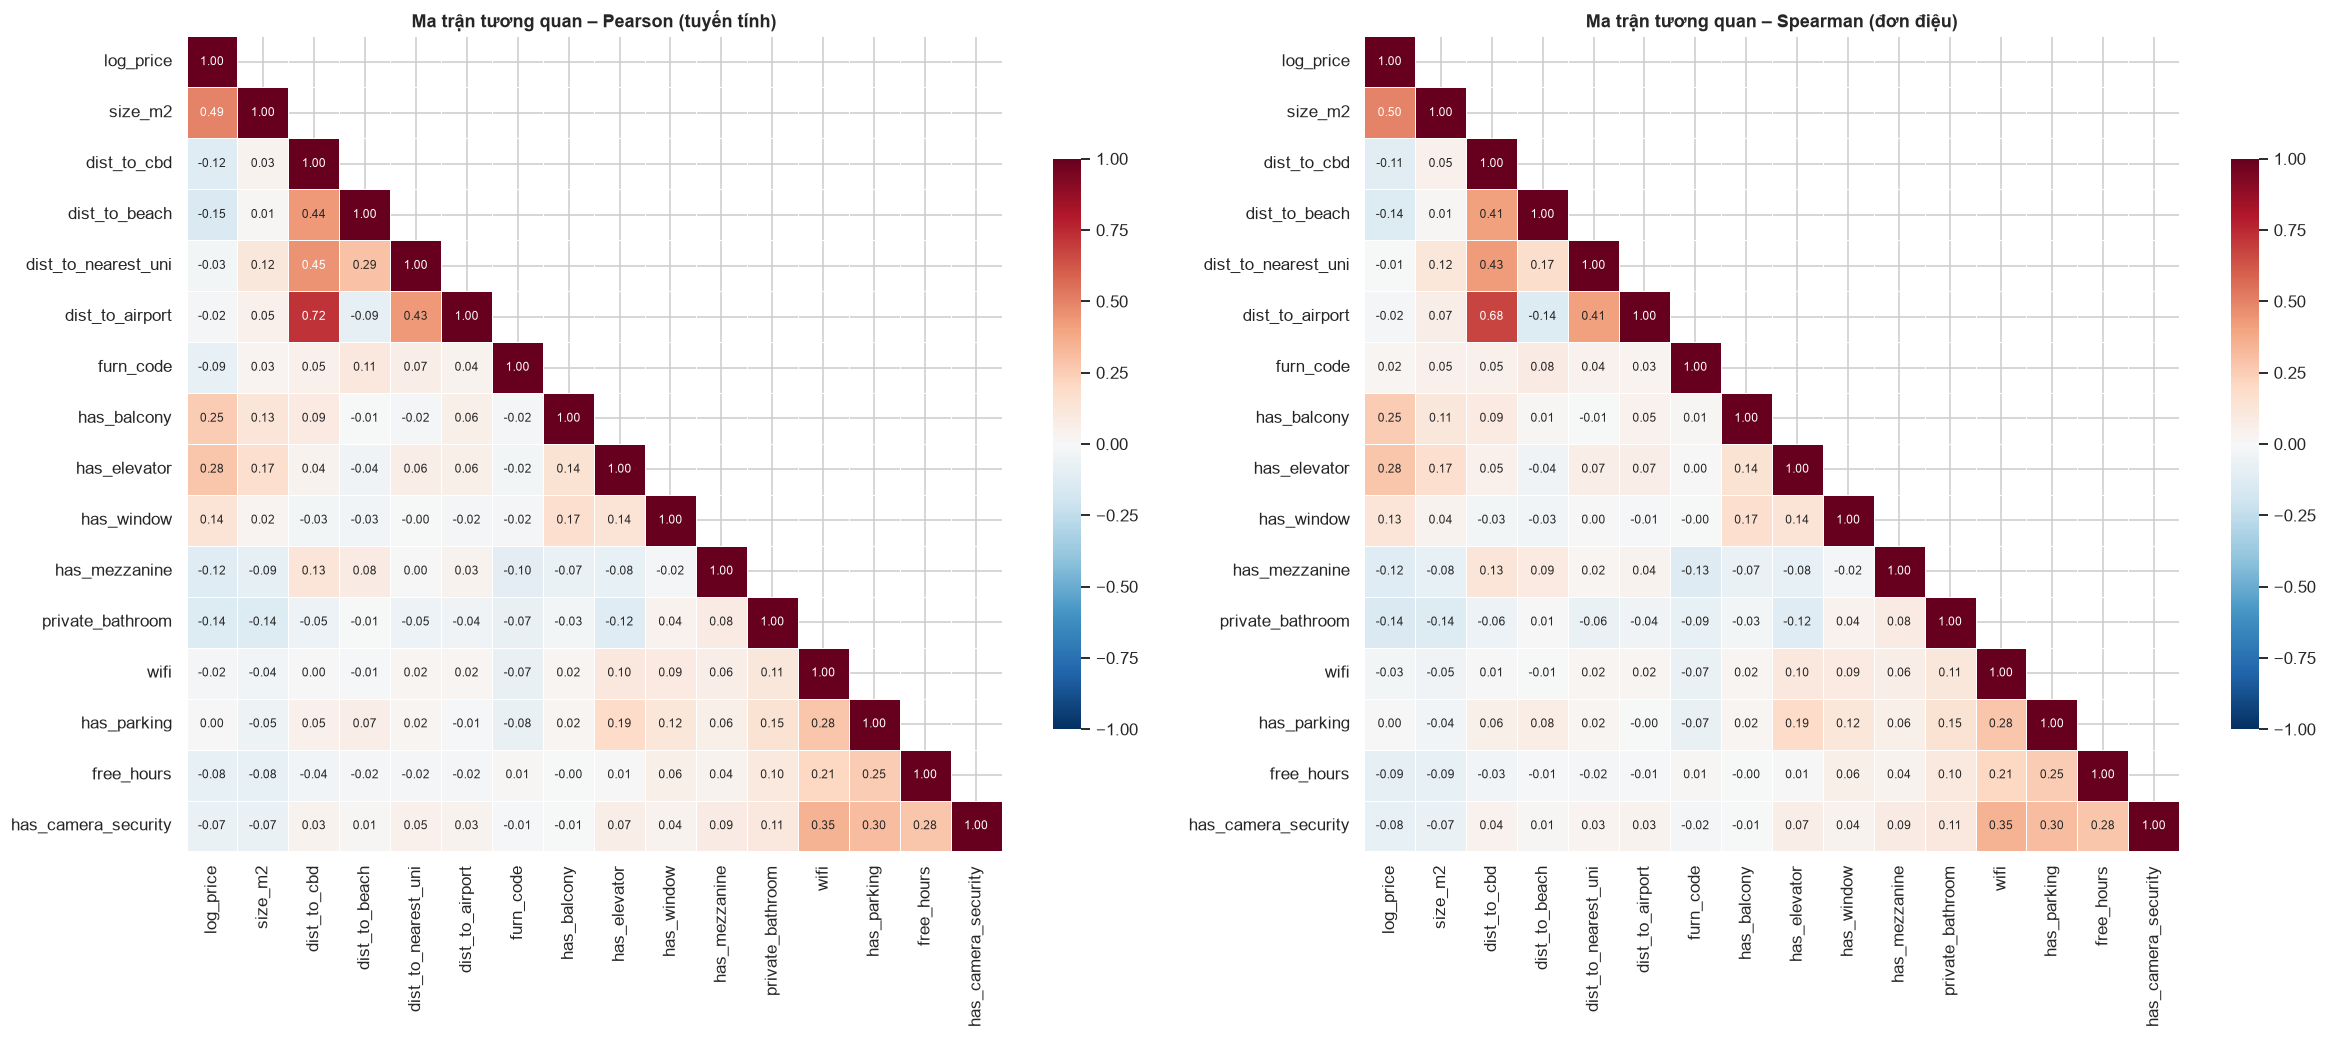

In [45]:
num_cols = ["log_price", "size_m2"] + (["rooms"] if ORD else []) + CONT[1:] + ["furn_code"] + BIN
corr_p = df[num_cols].corr(method="pearson"); corr_s = df[num_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr_p, dtype=bool), k=1)
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, cm, t in zip(axes, [corr_p, corr_s], ["Pearson (tuyến tính)", "Spearman (đơn điệu)"]):
    sns.heatmap(cm, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
                linewidths=.5, annot_kws={"size": 8}, cbar_kws={"shrink": .7}, ax=ax)
    ax.set_title(f"Ma trận tương quan – {t}")
plt.tight_layout(); plt.show()

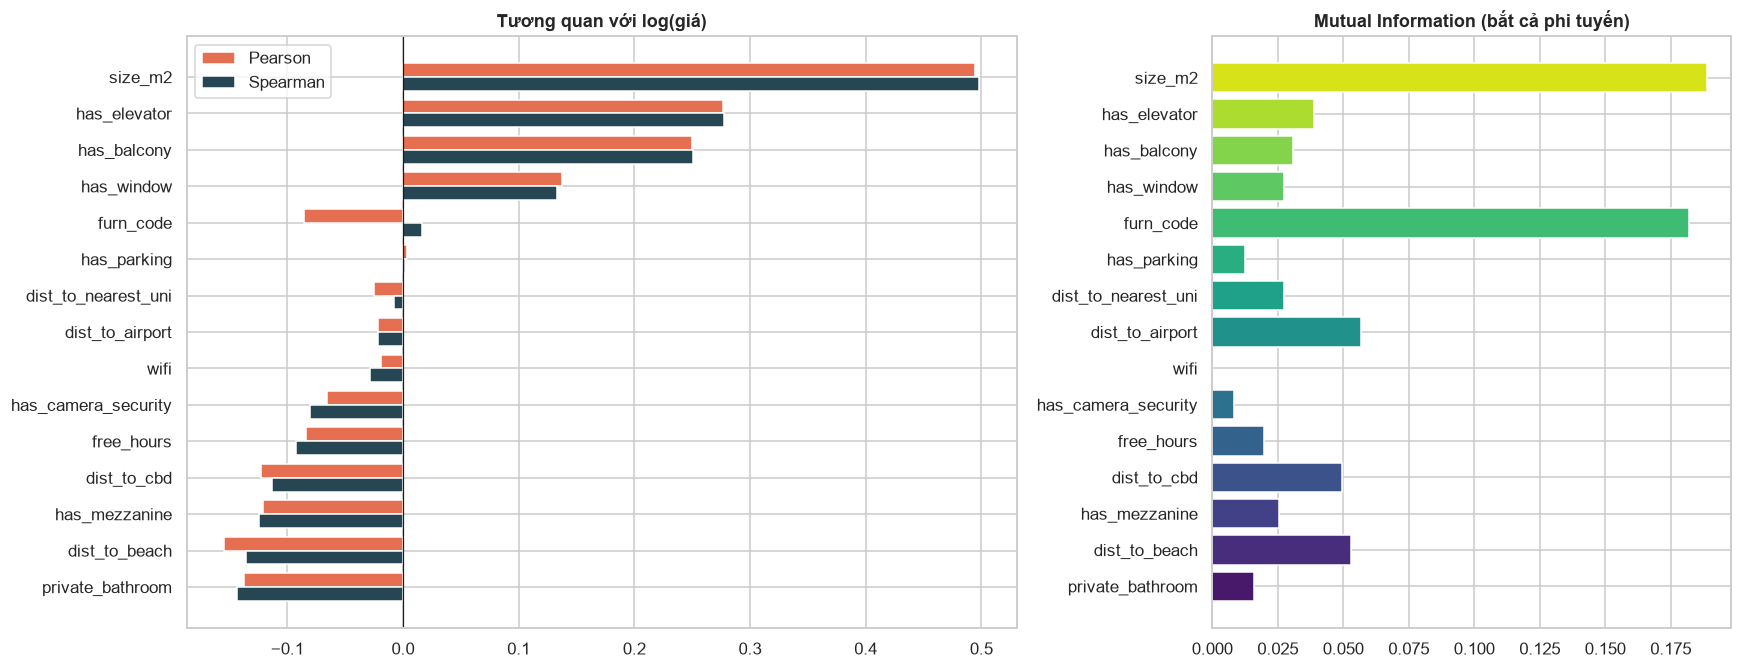

Cặp biến tương quan mạnh với nhau (|r| > 0.5) – nguy cơ đa cộng tuyến:


,biến A,biến B,r
82,dist_to_airport,dist_to_cbd,0.721000


In [46]:
# Xếp hạng ảnh hưởng tới log giá: Pearson vs Spearman vs Mutual Information
feat_rank = [c for c in num_cols if c != "log_price"]
Xmi = df[feat_rank].values; mi = mutual_info_regression(Xmi, df.log_price.values, random_state=42,
        discrete_features=[f in BIN+ORD+["furn_code"] for f in feat_rank])
rank = pd.DataFrame({"Pearson": corr_p.loc[feat_rank, "log_price"], "Spearman": corr_s.loc[feat_rank, "log_price"], "MI": mi}).sort_values("Spearman")
fig, axes = plt.subplots(1, 2, figsize=(16, max(5, .35*len(rank)+1)), gridspec_kw={"width_ratios": [1.6, 1]})
y = np.arange(len(rank)); h = .38
axes[0].barh(y+h/2, rank.Pearson, h, color="#E76F51", label="Pearson"); axes[0].barh(y-h/2, rank.Spearman, h, color="#264653", label="Spearman")
axes[0].set_yticks(y); axes[0].set_yticklabels(rank.index); axes[0].axvline(0, color="k", lw=.8); axes[0].legend()
axes[0].set_title("Tương quan với log(giá)")
axes[1].barh(rank.index, rank.MI, color=sns.color_palette("viridis", len(rank))); axes[1].set_title("Mutual Information (bắt cả phi tuyến)")
plt.tight_layout(); plt.show()

hi = corr_p.where(~mask).stack().reset_index(); hi.columns = ["biến A", "biến B", "r"]
hi = hi[(hi.r.abs() > .5) & (hi["biến A"] != hi["biến B"]) & (hi["biến A"] != "log_price") & (hi["biến B"] != "log_price")].sort_values("r", key=abs, ascending=False)
print("Cặp biến tương quan mạnh với nhau (|r| > 0.5) – nguy cơ đa cộng tuyến:")
display(hi.round(3).style.background_gradient(subset=["r"], cmap="RdBu_r", vmin=-1, vmax=1) if len(hi) else "Không có cặp nào")

## 6️⃣ Khoảng cách tới **trường ĐH** & **biển** – ảnh hưởng theo từng khoảng
Giả thuyết: tác động của khoảng cách **không đồng đều** – gần (<1 km) giá thay đổi khác với vùng 1–2 km và 2–6 km.
Ta chia 3 đoạn **0–1 km**, **1–2 km**, **2–6 km**, hồi quy tuyến tính riêng từng đoạn trên log-giá. Hệ số cho biết **mỗi +1 km thì giá đổi bao nhiêu %**.
Cột *kiểm soát diện tích* là hệ số sau khi loại ảnh hưởng của diện tích (tránh nhiễu do phòng gần trường thường nhỏ hơn).

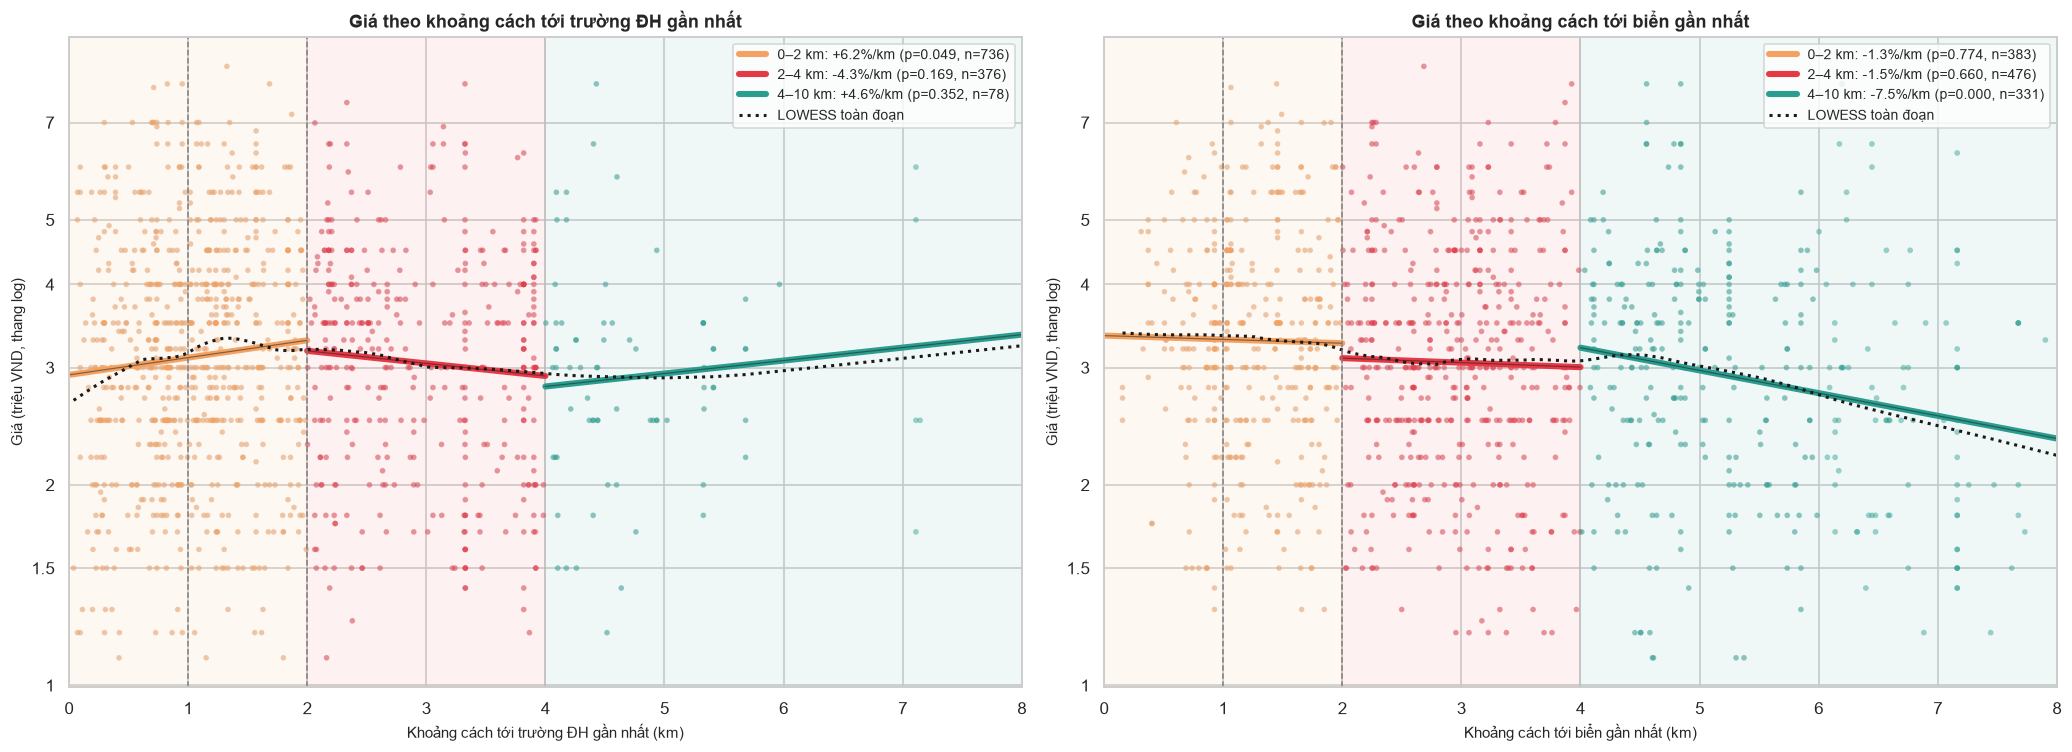


▶ trường ĐH gần nhất


,doan,n,gia_tb_trieu,gia_tv_trieu,he_so,pct_moi_km,p,R2,pct_kiem_soat_dt,p_ks
0,0–2 km,736,3.375000,3.100000,0.060000,6.158000,0.049000,0.005000,4.751000,0.070000
1,2–4 km,376,3.285000,3.200000,-0.043000,-4.255000,0.169000,0.005000,-6.586000,0.018000
2,4–10 km,78,3.132000,3.000000,0.045000,4.582000,0.352000,0.011000,3.664000,0.405000



▶ biển gần nhất


,doan,n,gia_tb_trieu,gia_tv_trieu,he_so,pct_moi_km,p,R2,pct_kiem_soat_dt,p_ks
0,0–2 km,383,3.541000,3.300000,-0.013000,-1.311000,0.774000,0.000000,2.372000,0.552000
1,2–4 km,476,3.307000,3.000000,-0.016000,-1.547000,0.660000,0.000000,-3.217000,0.288000
2,4–10 km,331,3.123000,3.000000,-0.078000,-7.549000,0.000000,0.037000,-8.408000,0.000000


In [47]:
SEGS = [(0, 2, "#F4A261"), (2, 4, "#E63946"), (4, 10, "#2A9D8F")]
DV = {"dist_to_nearest_uni": "trường ĐH gần nhất", "dist_to_beach": "biển gần nhất"}

def seg_fit(d, f):
    out = []
    for lo, hi, col in SEGS:
        s = d[(d[f] >= lo) & (d[f] < hi)]
        if len(s) < 15: continue
        m1 = smf.ols(f"log_price ~ {f}", s).fit()
        m2 = smf.ols(f"log_price ~ {f} + log_size", s).fit()
        out.append(dict(doan=f"{lo}–{hi} km", n=len(s), gia_tb_trieu=s.price_m.mean(), gia_tv_trieu=s.price_m.median(),
                        he_so=m1.params[f], pct_moi_km=(np.exp(m1.params[f])-1)*100, p=m1.pvalues[f], R2=m1.rsquared,
                        pct_kiem_soat_dt=(np.exp(m2.params[f])-1)*100, p_ks=m2.pvalues[f]))
    return pd.DataFrame(out)

fig, axes = plt.subplots(1, 2, figsize=(19, 7)); seg_tables = {}
for ax, (f, name) in zip(axes, DV.items()):
    d = df[df[f] < 6]
    ax.scatter(d[f], d.price_m, s=10, color="#B0BEC5", alpha=.35, edgecolor="none")
    tbl = seg_fit(df, f); seg_tables[f] = tbl
    for (lo, hi, col) in SEGS:
        s = df[(df[f] >= lo) & (df[f] < hi)]
        if len(s) < 15: continue
        ax.axvspan(lo, hi, color=col, alpha=.07)
        ax.scatter(s[f], s.price_m, s=14, color=col, alpha=.45, edgecolor="none")
        b1, b0 = np.polyfit(s[f], s.log_price, 1); xs = np.linspace(lo, hi, 50)
        r = tbl[tbl.doan == f"{lo}–{hi} km"].iloc[0]
        ax.plot(xs, np.exp(b0+b1*xs)/1e6, color=col, lw=4, solid_capstyle="round",
                label=f"{lo}–{hi} km: {r.pct_moi_km:+.1f}%/km (p={r.p:.3f}, n={int(r.n)})")
        ax.plot(xs, np.exp(b0+b1*xs)/1e6, color="k", lw=.8, alpha=.5)
    lw = lowess(df.log_price[df[f] < 10], df[f][df[f] < 10], frac=.3); ax.plot(lw[:, 0], np.exp(lw[:, 1])/1e6, "k:", lw=2, label="LOWESS toàn đoạn")
    for v in (1, 2): ax.axvline(v, color="gray", ls="--", lw=1)
    logax(ax, "y")
    ax.set(xlabel=f"Khoảng cách tới {name} (km)", ylabel="Giá (triệu VND, thang log)", xlim=(0, 8),
           title=f"Giá theo khoảng cách tới {name}"); ax.legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()
for f, name in DV.items():
    print(f"\n▶ {name}"); display(seg_tables[f].round(3).style.background_gradient(subset=["pct_moi_km", "pct_kiem_soat_dt"], cmap="RdYlGn", vmin=-25, vmax=25))

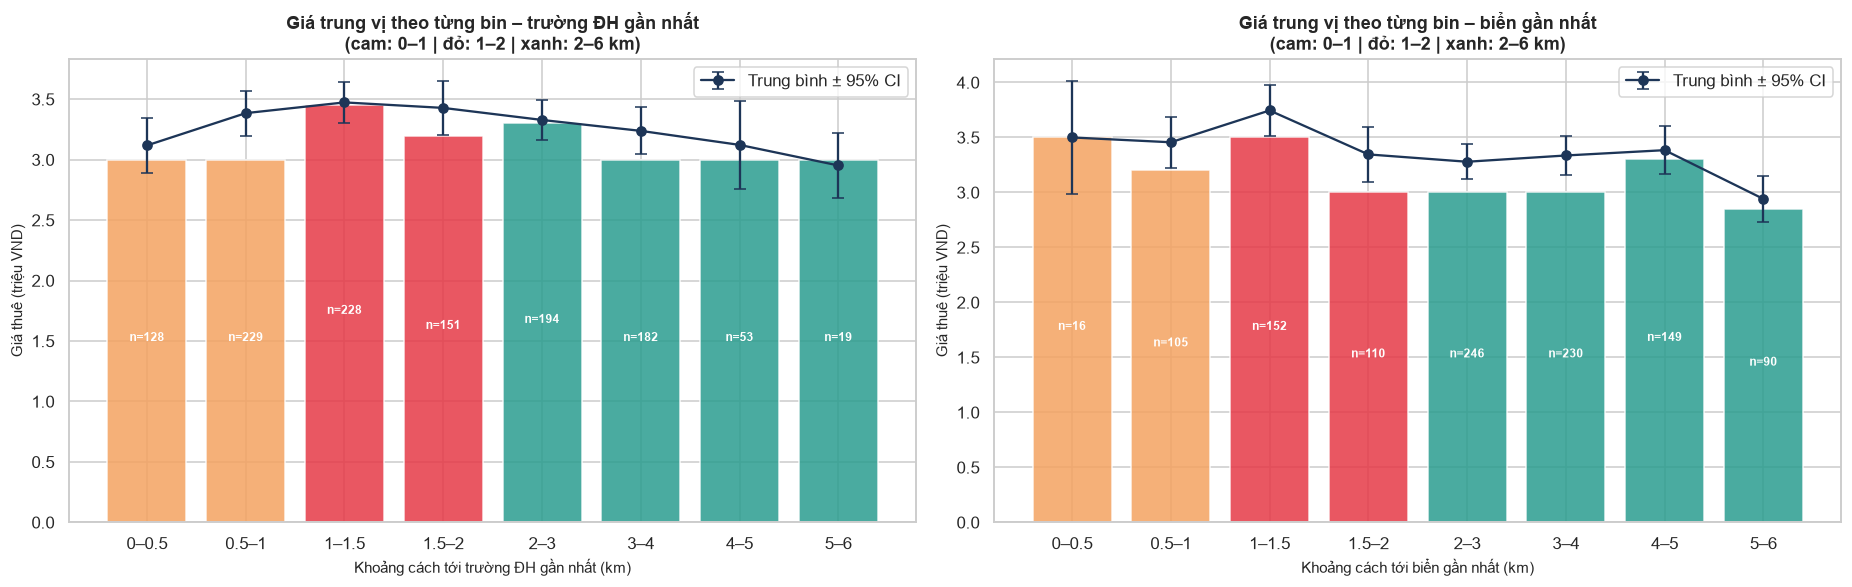

In [48]:
# Giá trung vị & khoảng tin cậy theo từng khoảng nhỏ (bin 0.5 km) – nhìn thẳng quy luật không cần mô hình
bins = [0, .5, 1, 1.5, 2, 3, 4, 5, 6]
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for ax, (f, name) in zip(axes, DV.items()):
    d = df[df[f] < 6].copy(); d["bin"] = pd.cut(d[f], bins)
    g = d.groupby("bin", observed=True).price_m.agg(["median", "mean", "count", "sem"])
    pos = np.arange(len(g)); colors = ["#F4A261" if i < 2 else "#E63946" if i < 4 else "#2A9D8F" for i in range(len(g))]
    ax.bar(pos, g["median"], color=colors, alpha=.85, edgecolor="white")
    ax.errorbar(pos, g["mean"], yerr=1.96*g["sem"], fmt="o-", color="#1D3557", capsize=4, label="Trung bình ± 95% CI")
    for p, (m, n) in enumerate(zip(g["median"], g["count"])): ax.text(p, m/2, f"n={n}", ha="center", color="white", fontsize=8, fontweight="bold")
    ax.set_xticks(pos); ax.set_xticklabels([f"{i.left:g}–{i.right:g}" for i in g.index]); ax.legend()
    ax.set(xlabel=f"Khoảng cách tới {name} (km)", ylabel="Giá thuê (triệu VND)", title=f"Giá trung vị theo từng bin – {name}\n(cam: 0–1 | đỏ: 1–2 | xanh: 2–6 km)")
plt.tight_layout(); plt.show()

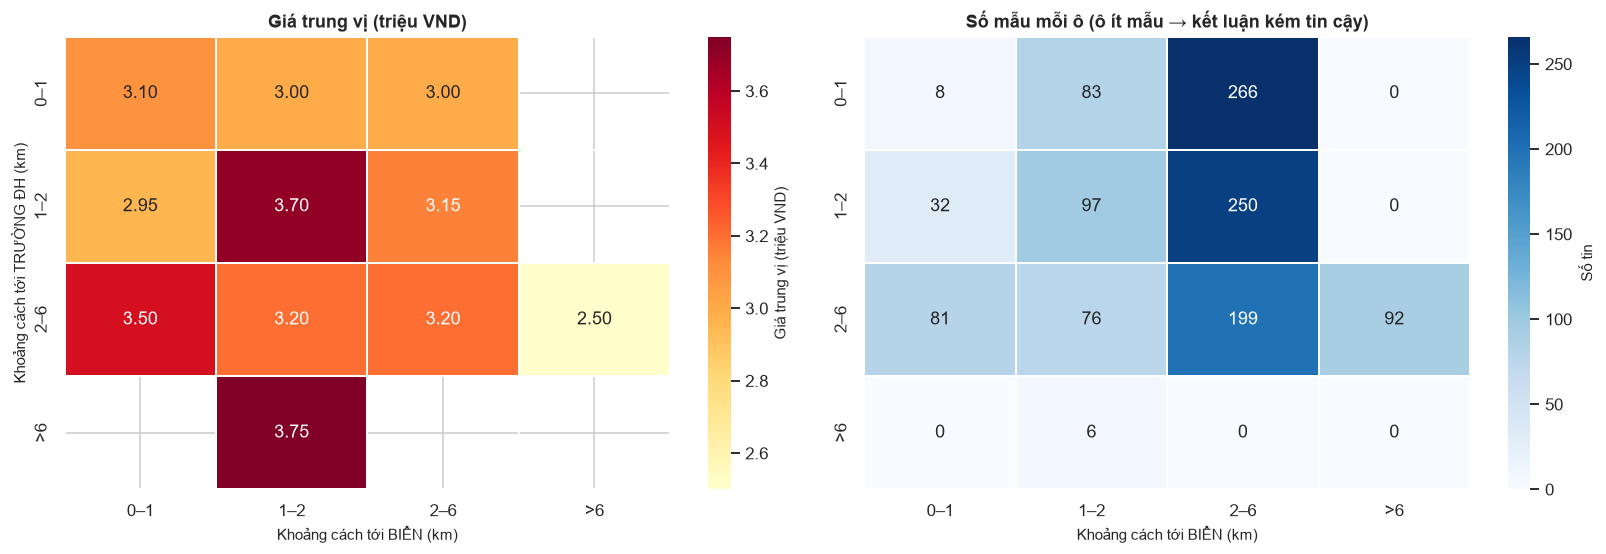

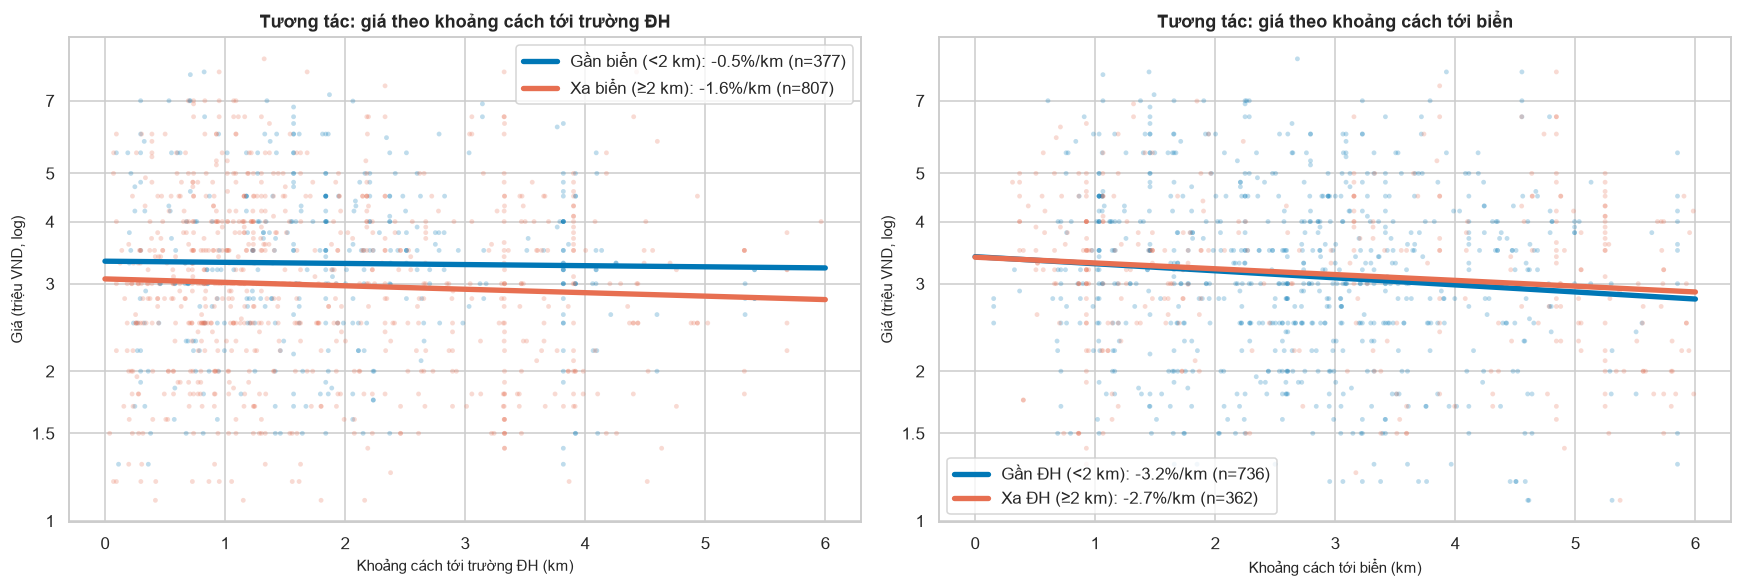

In [49]:
# Tác động CHUNG của cả hai khoảng cách: heatmap giá trung vị theo (khoảng cách ĐH) x (khoảng cách biển)
ub = pd.cut(df.dist_to_nearest_uni, [0, 1, 2, 6, np.inf], labels=["0–1", "1–2", "2–6", ">6"])
bb = pd.cut(df.dist_to_beach, [0, 1, 2, 6, np.inf], labels=["0–1", "1–2", "2–6", ">6"])
med = df.groupby([ub, bb], observed=False).price_m.median().unstack(); cnt = df.groupby([ub, bb], observed=False).size().unstack()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
sns.heatmap(med, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=1, ax=axes[0], cbar_kws={"label": "Giá trung vị (triệu VND)"})
axes[0].set(title="Giá trung vị (triệu VND)", xlabel="Khoảng cách tới BIỂN (km)", ylabel="Khoảng cách tới TRƯỜNG ĐH (km)")
sns.heatmap(cnt, annot=True, fmt="d", cmap="Blues", linewidths=1, ax=axes[1], cbar_kws={"label": "Số tin"})
axes[1].set(title="Số mẫu mỗi ô (ô ít mẫu → kết luận kém tin cậy)", xlabel="Khoảng cách tới BIỂN (km)", ylabel="")
plt.tight_layout(); plt.show()

# Tương tác: độ dốc giá theo khoảng cách ĐH có khác nhau giữa nhóm gần biển và xa biển?
near = df.dist_to_beach < 2
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, (xf, grp, name) in zip(axes, [("dist_to_nearest_uni", near, "trường ĐH"), ("dist_to_beach", df.dist_to_nearest_uni < 2, "biển")]):
    gl = ["Gần biển (<2 km)", "Xa biển (≥2 km)"] if xf == "dist_to_nearest_uni" else ["Gần ĐH (<2 km)", "Xa ĐH (≥2 km)"]
    for flag, lab, col in [(True, gl[0], "#0077B6"), (False, gl[1], "#E76F51")]:
        s = df[(grp == flag) & (df[xf] < 6)]
        ax.scatter(s[xf], s.price_m, s=10, color=col, alpha=.25, edgecolor="none")
        b1, b0 = np.polyfit(s[xf], s.log_price, 1); xs = np.linspace(0, 6, 50)
        ax.plot(xs, np.exp(b0+b1*xs)/1e6, color=col, lw=3.5, label=f"{lab}: {(np.exp(b1)-1)*100:+.1f}%/km (n={len(s)})")
    logax(ax, "y"); ax.legend()
    ax.set(xlabel=f"Khoảng cách tới {name} (km)", ylabel="Giá (triệu VND, log)", title=f"Tương tác: giá theo khoảng cách tới {name}")
plt.tight_layout(); plt.show()

## 7️⃣ Biến phân loại & bản đồ giá
Sắp theo **giá trung vị**; số trong ngoặc là số mẫu. Nhóm quá ít mẫu (< 10) sẽ không ổn định khi học.

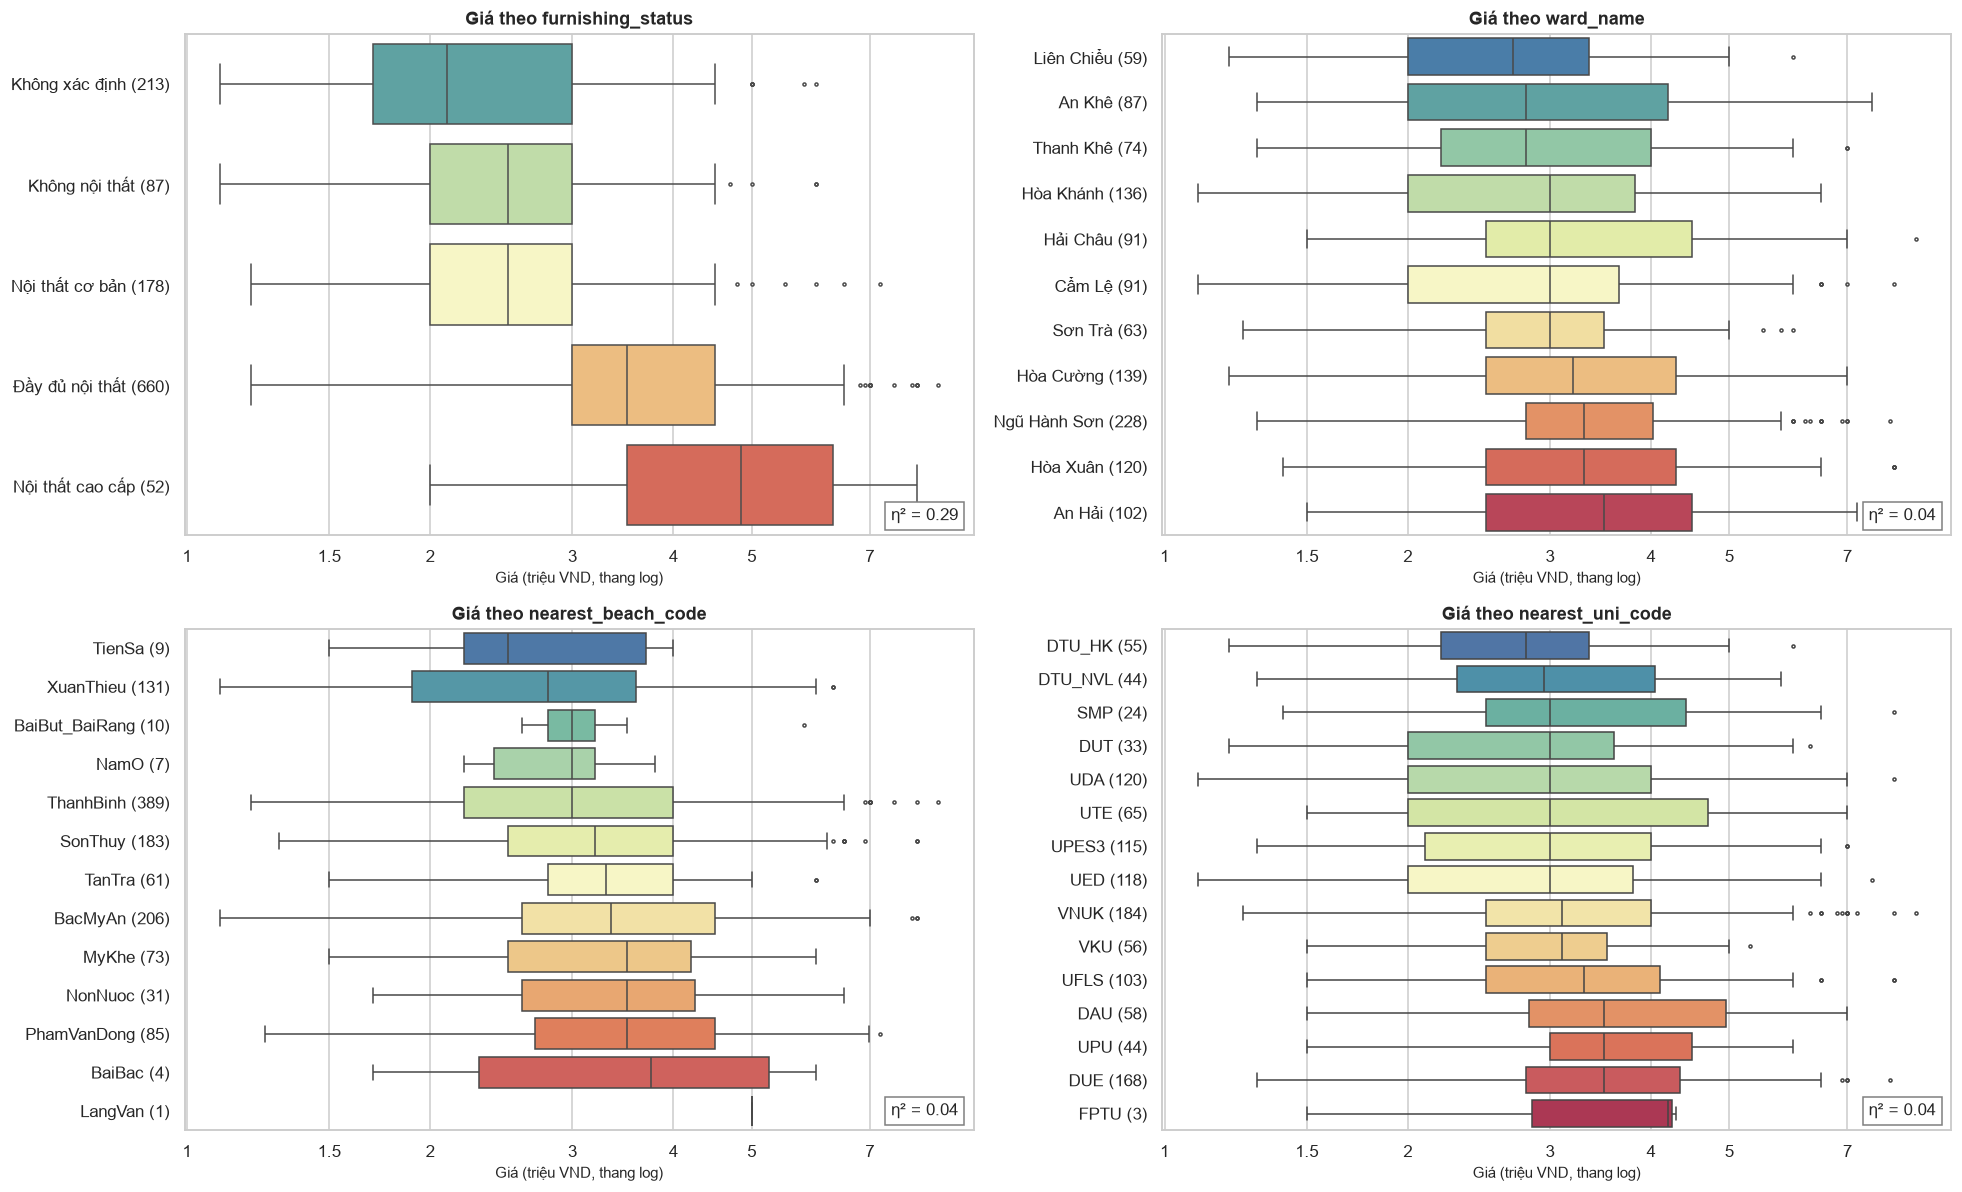

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11)); axes = axes.ravel()
for ax, f in zip(axes, CAT):
    order = df.groupby(f).log_price.median().sort_values().index
    n = df[f].value_counts()
    sns.boxplot(y=f, x="price_m", data=df, order=order, palette="Spectral_r", ax=ax, fliersize=2, linewidth=1)
    ax.set_yticklabels([f"{o} ({n[o]})" for o in order]); logax(ax, "x")
    ax.set(xlabel="Giá (triệu VND, thang log)", ylabel="", title=f"Giá theo {f}")
    # η² : mức độ biến phân loại giải thích được log giá
    grp = [g.log_price.values for _, g in df.groupby(f)]; ssb = sum(len(g)*(g.mean()-df.log_price.mean())**2 for g in grp)
    ax.text(.98, .03, f"η² = {ssb/((df.log_price-df.log_price.mean())**2).sum():.2f}", transform=ax.transAxes, ha="right", fontsize=11, bbox=dict(fc="white", ec="gray"))
plt.tight_layout(); plt.show()

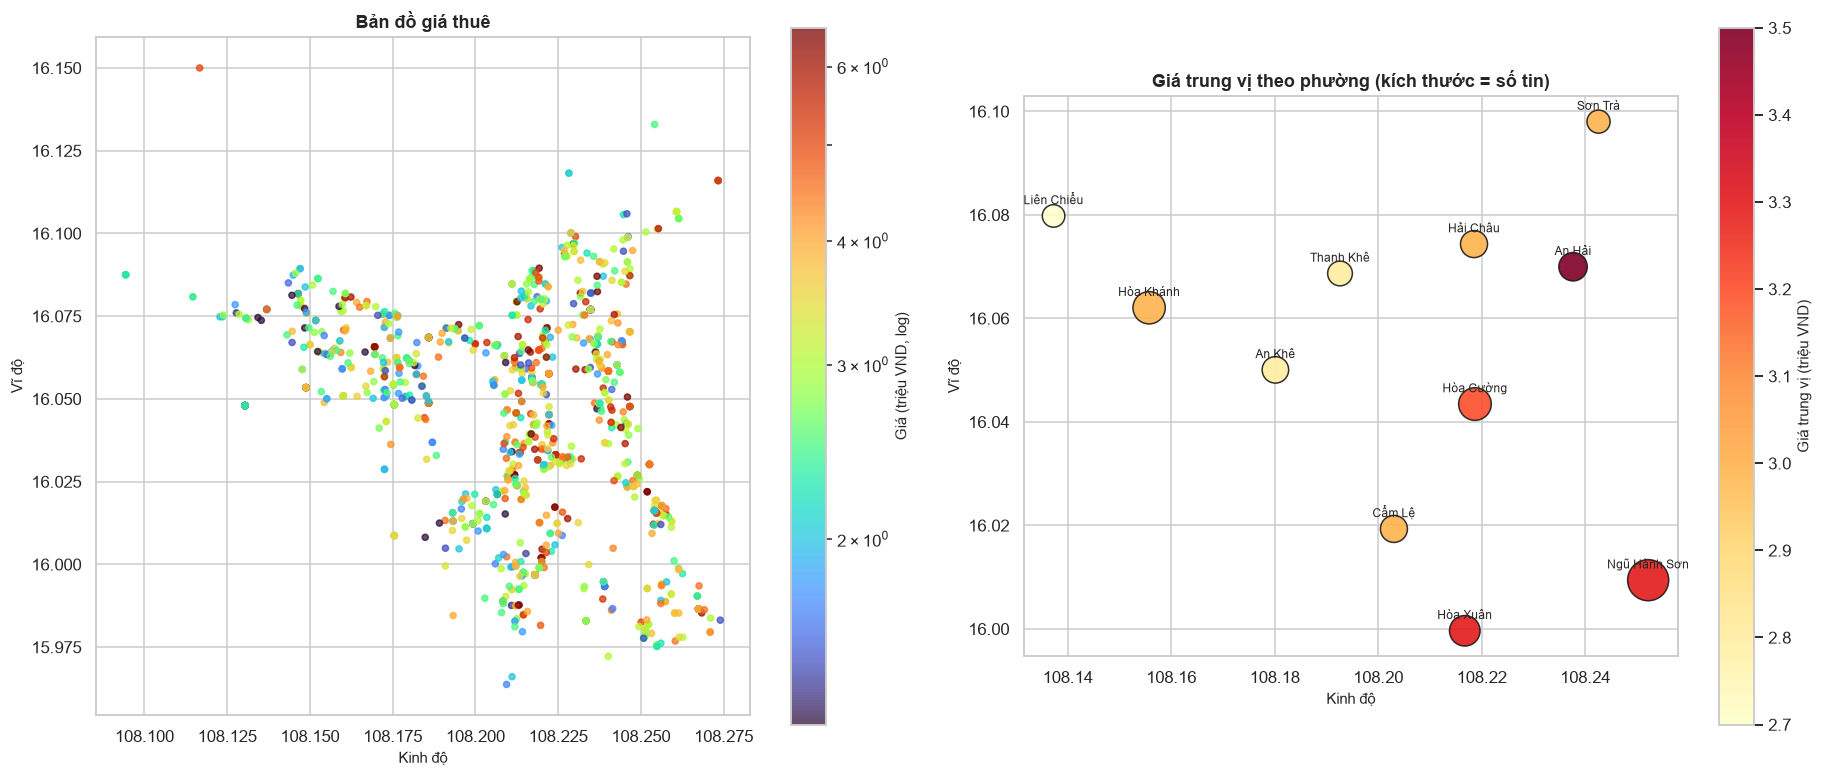

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sc = axes[0].scatter(df.longitude, df.latitude, c=df.price_m, s=16, cmap="turbo", alpha=.75, norm=plt.matplotlib.colors.LogNorm(df.price_m.quantile(.02), df.price_m.quantile(.98)))
plt.colorbar(sc, ax=axes[0], label="Giá (triệu VND, log)"); axes[0].set(title="Bản đồ giá thuê", xlabel="Kinh độ", ylabel="Vĩ độ"); axes[0].set_aspect(1)
w = df.groupby("ward_name").agg(price=("price_m", "median"), n=("price_m", "size"), lat=("latitude", "mean"), lon=("longitude", "mean"))
sc2 = axes[1].scatter(w.lon, w.lat, s=w.n*3+40, c=w.price, cmap="YlOrRd", edgecolor="k", alpha=.9)
for nme, r in w.iterrows(): axes[1].annotate(nme, (r.lon, r.lat), fontsize=8, ha="center", va="bottom", xytext=(0, 6), textcoords="offset points")
plt.colorbar(sc2, ax=axes[1], label="Giá trung vị (triệu VND)"); axes[1].set(title="Giá trung vị theo phường (kích thước = số tin)", xlabel="Kinh độ", ylabel="Vĩ độ"); axes[1].set_aspect(1)
plt.tight_layout(); plt.show()

## 8️⃣ Tổng kết tự động & gợi ý cho bước huấn luyện

In [52]:
print("=" * 70); print(f"TỔNG KẾT EDA – {CATEGORY}  ({len(df):,} mẫu)"); print("=" * 70)
print(f"• Giá trung vị {df.price_m.median():.2f} triệu | TB {df.price_m.mean():.2f} | skew giá = {df.price_m.skew():.2f} → log giá skew = {df.log_price.skew():.2f}")
print("• Thuộc tính liên tục lệch phải mạnh (skew > 1):", [f for f in CONT if df[f].skew() > 1])
print("• Thuộc tính phi tuyến rõ (ΔR² > 0.02):", list(nl.index[nl.delta_R2 > .02]) or "không có")
print("• Top 5 biến tương quan Spearman mạnh nhất với giá:")
for k, v in rank.assign(a=rank.Spearman.abs()).sort_values("a", ascending=False).head(5).Spearman.items(): print(f"    - {k:22s} ρ = {v:+.2f}")
print("• Nhị phân quá hiếm (<5% hoặc >95%):", [f for f in BIN if not .05 <= df[f].mean() <= .95] or "không có")
for f in CAT: print(f"• Nhóm hiếm (<10 mẫu) trong {f}:", list(df[f].value_counts()[lambda s: s < 10].index) or "không có")
print("• Khoảng cách – tác động % mỗi +1 km (kiểm soát diện tích):")
for f, name in DV.items():
    print("    ", name, "→", ", ".join(f"{r.doan}: {r.pct_kiem_soat_dt:+.1f}%" for r in seg_tables[f].itertuples()))

TỔNG KẾT EDA – Phòng trọ  (1,190 mẫu)
• Giá trung vị 3.10 triệu | TB 3.33 | skew giá = 0.84 → log giá skew = -0.14
• Thuộc tính liên tục lệch phải mạnh (skew > 1): []
• Thuộc tính phi tuyến rõ (ΔR² > 0.02): không có
• Top 5 biến tương quan Spearman mạnh nhất với giá:
    - size_m2                ρ = +0.50
    - has_elevator           ρ = +0.28
    - has_balcony            ρ = +0.25
    - private_bathroom       ρ = -0.14
    - dist_to_beach          ρ = -0.14
• Nhị phân quá hiếm (<5% hoặc >95%): không có
• Nhóm hiếm (<10 mẫu) trong furnishing_status: không có
• Nhóm hiếm (<10 mẫu) trong ward_name: không có
• Nhóm hiếm (<10 mẫu) trong nearest_beach_code: ['TienSa', 'NamO', 'BaiBac', 'LangVan']
• Nhóm hiếm (<10 mẫu) trong nearest_uni_code: ['FPTU']
• Khoảng cách – tác động % mỗi +1 km (kiểm soát diện tích):
     trường ĐH gần nhất → 0–2 km: +4.8%, 2–4 km: -6.6%, 4–10 km: +3.7%
     biển gần nhất → 0–2 km: +2.4%, 2–4 km: -3.2%, 4–10 km: -8.4%


### 📌 Kết luận EDA – Phòng trọ (1.151 mẫu sau làm sạch)
**Phân bổ**
- Giá lệch phải nhẹ (skew ≈ 0,8), sau `log` gần đối xứng → huấn luyện trên `log(giá)` là hợp lý. Các khoảng cách không lệch mạnh (skew < 1).
- Giá và diện tích có dạng **rời rạc theo mốc** (2; 2,5; 3; 3,5 triệu…, 20/25/30 m²) → sai số dự đoán khó xuống thấp hơn mức "nhảy bậc" này.
- Nhãn nhị phân khá cân bằng; nhóm hiếm (<10 mẫu): `nearest_beach_code` (TienSa, NamO, BaiBac, LangVan) và `nearest_uni_code` (FPTU) → giữ `MIN_FREQ` gộp nhóm hiếm.

**Tuyến tính hay phi tuyến?**
- **Hầu hết gần tuyến tính** (ΔR² giữa spline và tuyến tính ≈ 0). Chỉ `size_m2` có tương quan đáng kể (ρ ≈ 0,51), tiếp theo là `has_elevator`, `has_balcony`.
- Dùng `log(size_m2)` là phù hợp cho mô hình tuyến tính (quan hệ log–log ổn định).
- `dist_to_nearest_uni` và `dist_to_airport` gần như **không có ảnh hưởng tuyến tính** toàn cục.

**Khoảng cách tới ĐH / biển theo từng đoạn**
- ĐH: 0–1 km giá có xu hướng *tăng* nhẹ (+19%/km, p≈0,07), 1–2 km giảm nhẹ (−7%/km, không có ý nghĩa), 2–6 km giảm (−4%/km, p≈0,05). Hiệu ứng yếu, đường cong có "đỉnh" quanh 1–1,5 km.
- Biển: tất cả các đoạn đều giảm nhẹ và **không có ý nghĩa thống kê** (p > 0,3) – nên không kỳ vọng nhiều ở nhóm trọ.

**Gợi ý huấn luyện:** `log(giá)` làm đích; `log(size_m2)`; mô hình tuyến tính (Ridge) đã gần đủ, HGB có thể thêm vài % nhờ tương tác tiện ích × phường; cân nhắc đặc trưng phân đoạn khoảng cách (`min(d,1)`, `clip(d,1,2)`) nếu muốn bắt hiệu ứng ĐH.